In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

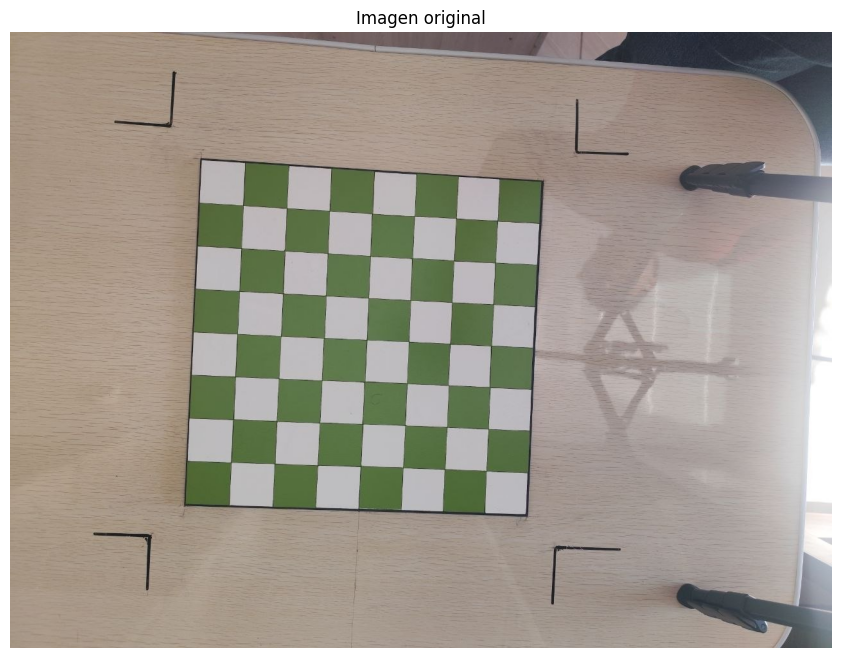

In [2]:
IMAGE_PATH = r"C:\Users\User\Desktop\Brazo Robotico\Dataset\Tableros\photo_1_2026-05-16_15-13-26.jpg"

img = cv2.imread(IMAGE_PATH)

if img is None:
    raise FileNotFoundError("No se pudo cargar la imagen. Revisa la ruta.")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(img_rgb)
plt.title("Imagen original")
plt.axis("off")
plt.show()

In [3]:
def ordenar_puntos(pts):
    pts = np.array(pts, dtype="float32")

    suma = pts.sum(axis=1)
    resta = np.diff(pts, axis=1)

    ordenados = np.zeros((4, 2), dtype="float32")
    ordenados[0] = pts[np.argmin(suma)]      # superior izquierda
    ordenados[2] = pts[np.argmax(suma)]      # inferior derecha
    ordenados[1] = pts[np.argmin(resta)]     # superior derecha
    ordenados[3] = pts[np.argmax(resta)]     # inferior izquierda

    return ordenados

In [4]:
def detectar_tablero(imagen_bgr, mostrar=True):
    img = imagen_bgr.copy()
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Suavizado para reducir ruido
    blur = cv2.GaussianBlur(gray, (5, 5), 0)

    # Detección de bordes
    edges = cv2.Canny(blur, 50, 150)

    # Dilatar bordes para unir líneas del tablero
    kernel = np.ones((5, 5), np.uint8)
    edges_dilated = cv2.dilate(edges, kernel, iterations=2)

    # Buscar contornos
    contours, _ = cv2.findContours(
        edges_dilated, 
        cv2.RETR_EXTERNAL, 
        cv2.CHAIN_APPROX_SIMPLE
    )

    candidatos = []

    for c in contours:
        area = cv2.contourArea(c)

        # Ignorar contornos pequeños
        if area < 10000:
            continue

        peri = cv2.arcLength(c, True)
        approx = cv2.approxPolyDP(c, 0.02 * peri, True)

        if len(approx) == 4:
            candidatos.append((area, approx))

    if len(candidatos) == 0:
        print("No se detectó un tablero rectangular automáticamente.")
        return None

    # Tomar el cuadrilátero más grande
    candidatos = sorted(candidatos, key=lambda x: x[0], reverse=True)
    tablero = candidatos[0][1].reshape(4, 2)

    if mostrar:
        img_debug = img.copy()
        cv2.drawContours(img_debug, [tablero.astype(int)], -1, (0, 255, 0), 5)

        plt.figure(figsize=(12, 8))
        plt.imshow(cv2.cvtColor(img_debug, cv2.COLOR_BGR2RGB))
        plt.title("Contorno detectado automáticamente")
        plt.axis("off")
        plt.show()

    return ordenar_puntos(tablero)

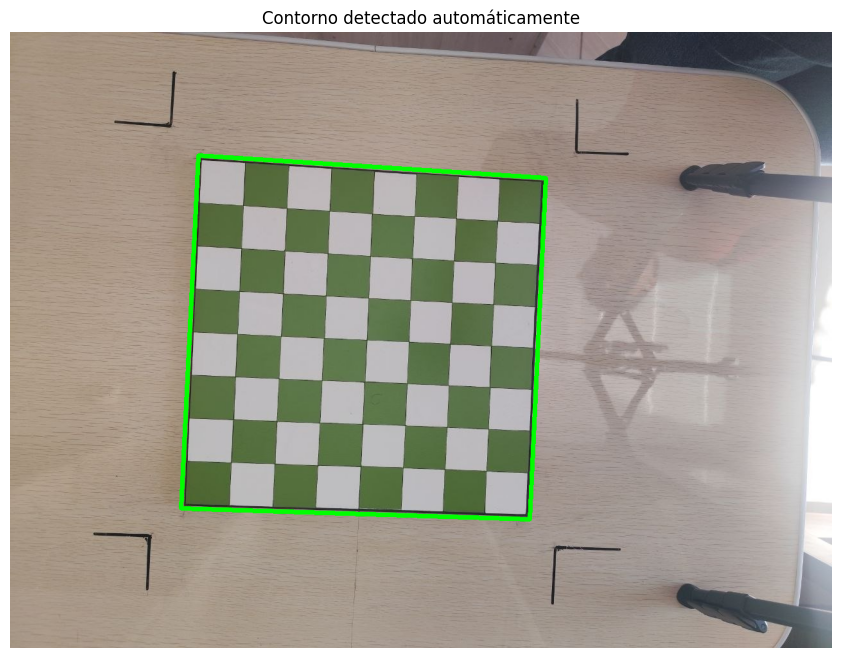

Esquinas detectadas:
[[293. 192.]
 [834. 227.]
 [809. 759.]
 [266. 742.]]


In [5]:
corners = detectar_tablero(img)

print("Esquinas detectadas:")
print(corners)

In [6]:
def enderezar_tablero(imagen_bgr, corners, size=800):
    corners = ordenar_puntos(corners)

    destino = np.array([
        [0, 0],
        [size - 1, 0],
        [size - 1, size - 1],
        [0, size - 1]
    ], dtype="float32")

    matriz = cv2.getPerspectiveTransform(corners, destino)

    tablero_warp = cv2.warpPerspective(
        imagen_bgr, 
        matriz, 
        (size, size)
    )

    return tablero_warp

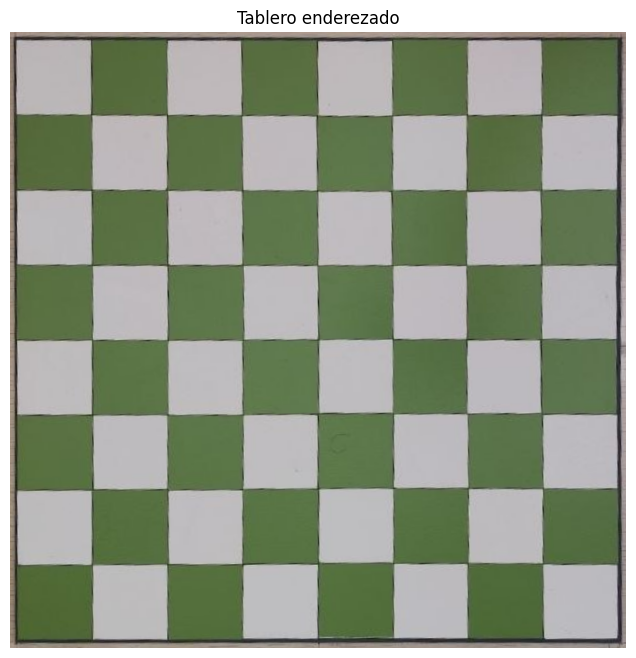

In [7]:
tablero_recto = enderezar_tablero(img, corners, size=800)

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(tablero_recto, cv2.COLOR_BGR2RGB))
plt.title("Tablero enderezado")
plt.axis("off")
plt.show()

In [29]:
def dibujar_grid(tablero_bgr, n=8):
    img_grid = tablero_bgr.copy()
    h, w = img_grid.shape[:2]

    cell_w = w // n
    cell_h = h // n

    for i in range(n + 1):
        x = i * cell_w
        y = i * cell_h

        cv2.line(img_grid, (x, 0), (x, h), (255, 0, 0), 2)
        cv2.line(img_grid, (0, y), (w, y), (255, 0, 0), 2)

    return img_grid

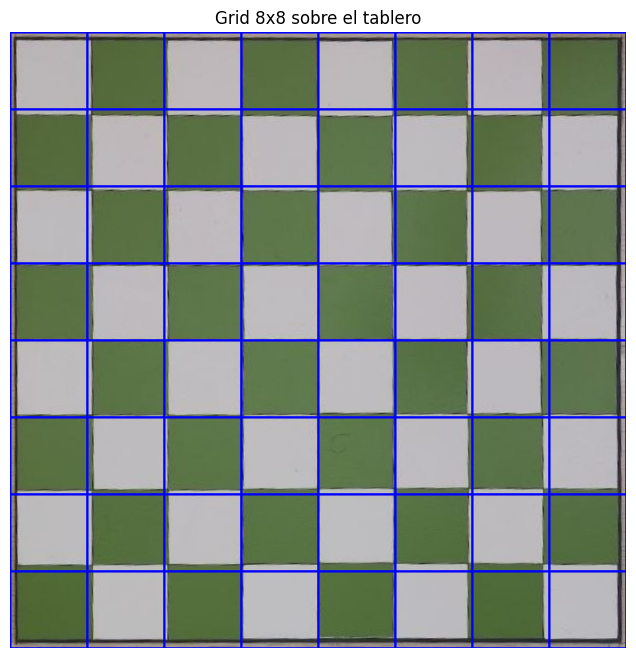

In [30]:
grid_img = dibujar_grid(tablero_recto)

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(grid_img, cv2.COLOR_BGR2RGB))
plt.title("Grid 8x8 sobre el tablero")
plt.axis("off")
plt.show()

In [25]:
def segmentar_casillas(tablero_bgr, output_dir="casillas_tablero", n=8):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    h, w = tablero_bgr.shape[:2]
    cell_h = h // n
    cell_w = w // n

    casillas = []

    for fila in range(n):
        for col in range(n):
            y1 = fila * cell_h
            y2 = (fila + 1) * cell_h
            x1 = col * cell_w
            x2 = (col + 1) * cell_w

            casilla = tablero_bgr[y1:y2, x1:x2]

            nombre = f"fila_{fila}_col_{col}.jpg"
            ruta = output_dir / nombre

            cv2.imwrite(str(ruta), casilla)

            casillas.append({
                "fila": fila,
                "columna": col,
                "imagen": casilla,
                "ruta": ruta
            })

    return casillas

In [12]:
casillas = segmentar_casillas(
    tablero_recto,
    output_dir="casillas_tablero",
    n=8
)

print(f"Se guardaron {len(casillas)} casillas.")
print("Directorio:", Path("casillas_tablero").resolve())

Se guardaron 64 casillas.
Directorio: C:\Users\User\Desktop\Brazo Robotico\Dataset\casillas_tablero


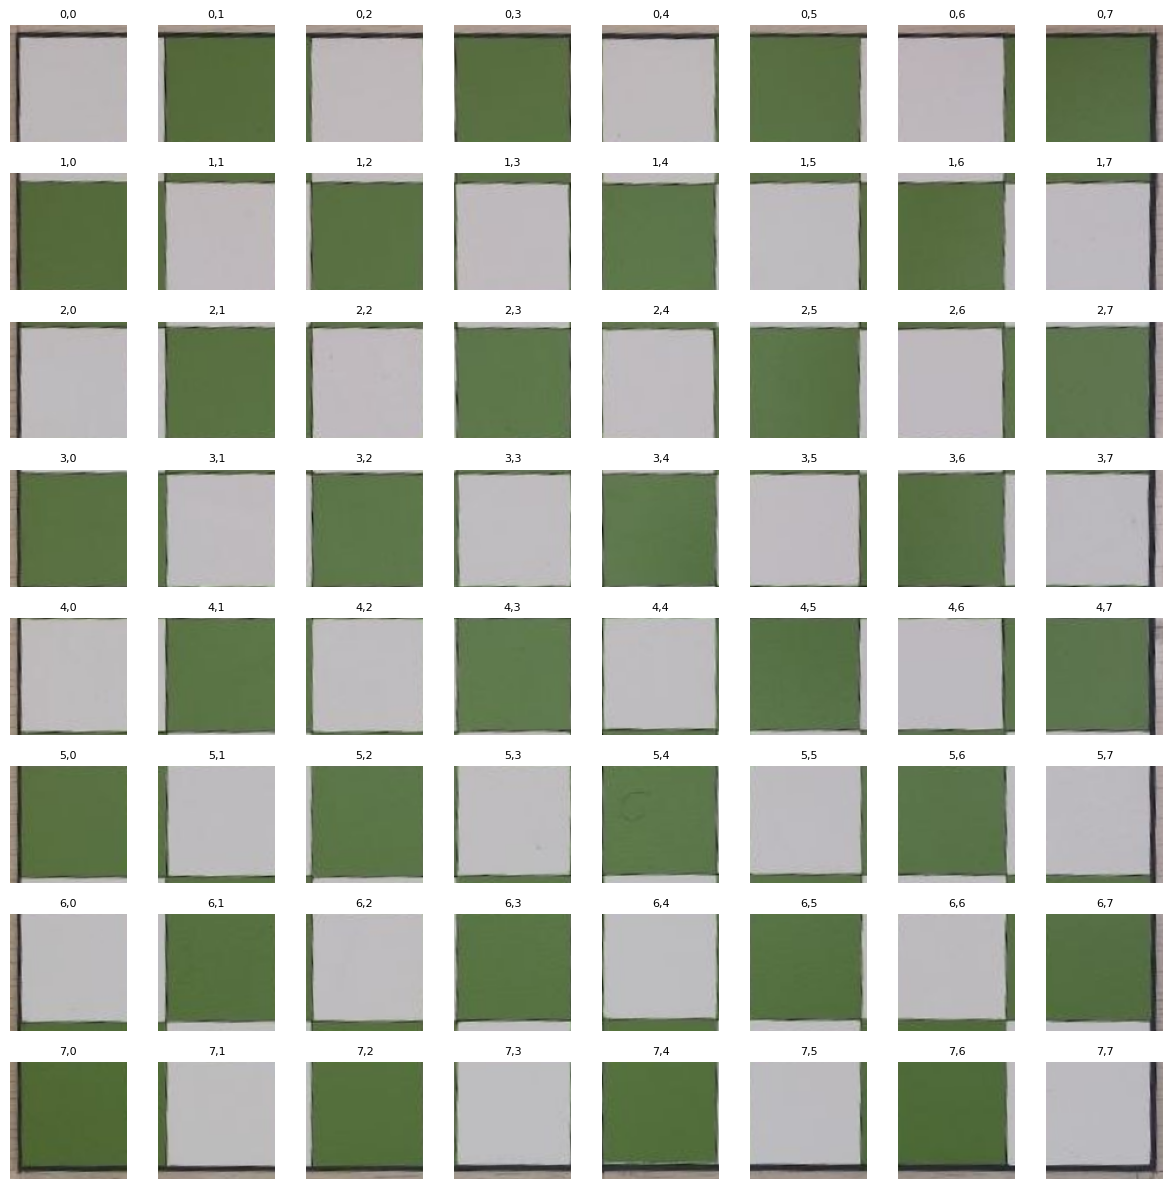

In [31]:
fig, axes = plt.subplots(8, 8, figsize=(12, 12))

for i, item in enumerate(casillas):
    fila = item["fila"]
    col = item["columna"]
    casilla_rgb = cv2.cvtColor(item["imagen"], cv2.COLOR_BGR2RGB)

    axes[fila, col].imshow(casilla_rgb)
    axes[fila, col].set_title(f"{fila},{col}", fontsize=8)
    axes[fila, col].axis("off")

plt.tight_layout()
plt.show()

In [10]:
cv2.imwrite("tablero_enderezado.jpg", tablero_recto)

print("Tablero enderezado guardado como tablero_enderezado.jpg")

Tablero enderezado guardado como tablero_enderezado.jpg


In [32]:
def nombre_casilla_ajedrez(fila, col):
    columnas = ["a", "b", "c", "d", "e", "f", "g", "h"]
    filas = ["8", "7", "6", "5", "4", "3", "2", "1"]

    return columnas[col] + filas[fila]

In [33]:
def segmentar_casillas_con_notacion(tablero_bgr, output_dir="casillas_ajedrez", n=8):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    h, w = tablero_bgr.shape[:2]
    cell_h = h // n
    cell_w = w // n

    casillas = []

    for fila in range(n):
        for col in range(n):
            y1 = fila * cell_h
            y2 = (fila + 1) * cell_h
            x1 = col * cell_w
            x2 = (col + 1) * cell_w

            casilla = tablero_bgr[y1:y2, x1:x2]

            nombre_ajedrez = nombre_casilla_ajedrez(fila, col)
            nombre_archivo = f"{nombre_ajedrez}.jpg"

            ruta = output_dir / nombre_archivo

            cv2.imwrite(str(ruta), casilla)

            casillas.append({
                "casilla": nombre_ajedrez,
                "fila": fila,
                "columna": col,
                "imagen": casilla,
                "ruta": ruta
            })

    return casillas

In [34]:
casillas_ajedrez = segmentar_casillas_con_notacion(
    tablero_recto,
    output_dir="casillas_ajedrez",
    n=8
)

print(f"Se guardaron {len(casillas_ajedrez)} casillas con notación de ajedrez.")
print("Directorio:", Path("casillas_ajedrez").resolve())

Se guardaron 64 casillas con notación de ajedrez.
Directorio: C:\Users\User\Desktop\Brazo Robotico\Dataset\casillas_ajedrez


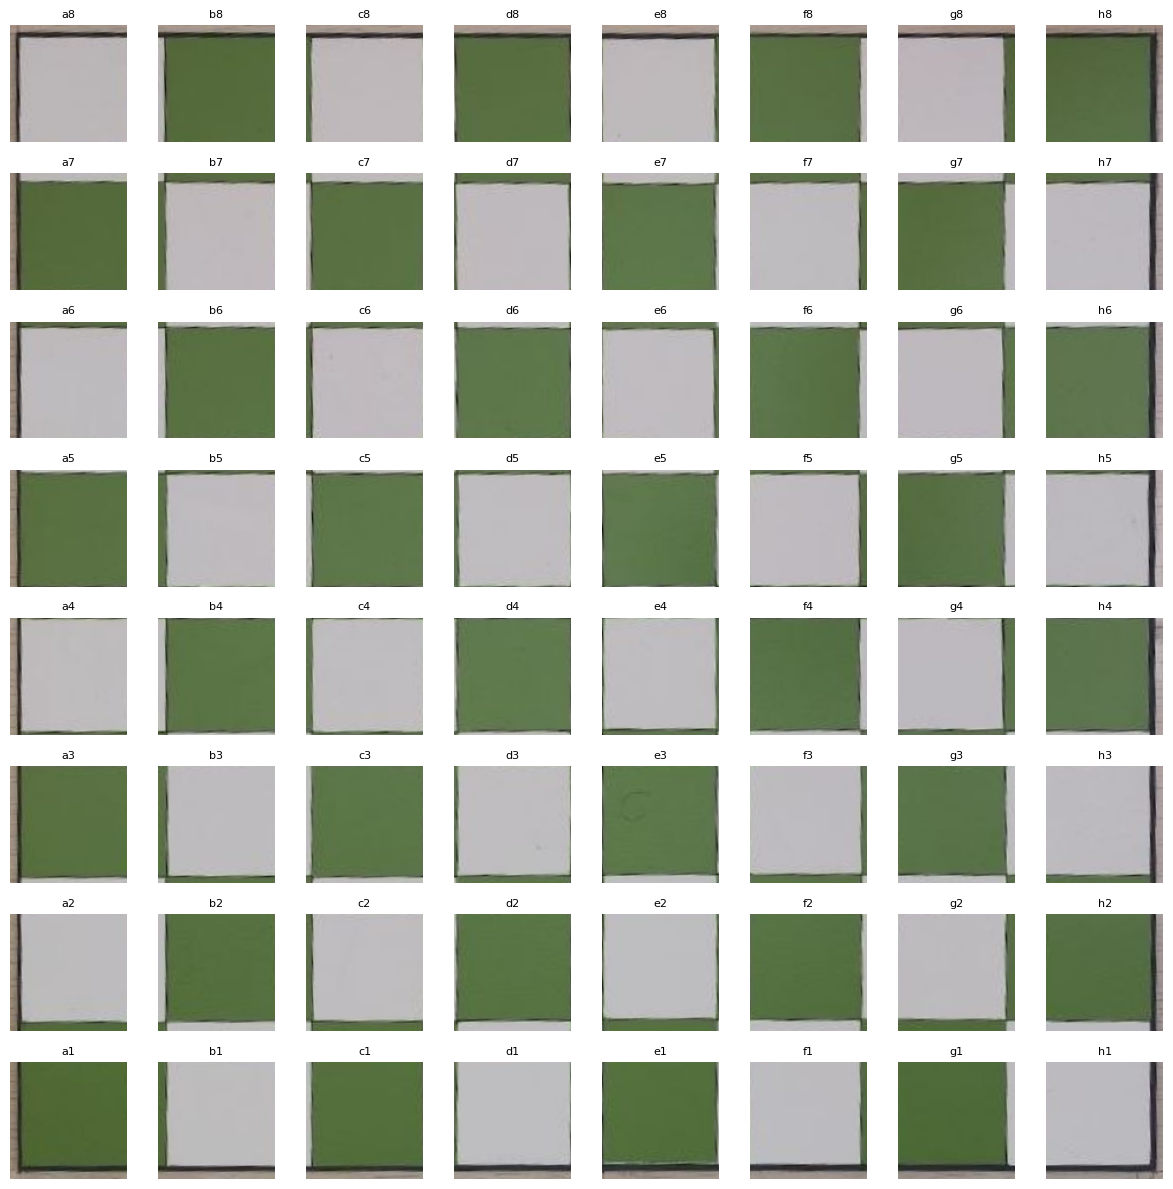

In [35]:
fig, axes = plt.subplots(8, 8, figsize=(12, 12))

for item in casillas_ajedrez:
    fila = item["fila"]
    col = item["columna"]
    nombre = item["casilla"]

    casilla_rgb = cv2.cvtColor(item["imagen"], cv2.COLOR_BGR2RGB)

    axes[fila, col].imshow(casilla_rgb)
    axes[fila, col].set_title(nombre, fontsize=8)
    axes[fila, col].axis("off")

plt.tight_layout()
plt.show()